# AI Prediction Scores

Compare the AI prediction scores in ClinVar variants and 1% variants.

In [2]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# range_d = {'esm1b':(-27,7),
#            'alpha_missense':(-.26,1.5),
#            'provean':(-17,8),
#            'pop_music':(-3,7),
#            'solvant_acc':(0,100),
#            'af_plddt':(0,100),
# }

## Loading data

### VarChAMP variants (~8k)

In [4]:
varchamp_al_df = pl.scan_csv("../../1_allele_collection/3_outputs/varchamp_consolidated_alleles_clinvar_gnomad.tsv", 
                            infer_schema_length=10000, 
                            separator="\t")
varchamp_al_df.collect()
# varchamp_al_df_ai_dedup.collect_schema().names()

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,f64
2,"""GBA""","""160G>C""","""Val54Leu""","""ENSG00000177628""","""1""",155240033,"""NC_000001.11:155240033:C:G""","""ALE0000584""","""CCSBVarC000001""","""6""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""F12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""G""","""C""","""1-155240033-G-C""",null
2,"""GBA""","""670C>T""","""Leu224Phe""","""ENSG00000177628""","""1""",155238225,"""NC_000001.11:155238225:G:A""","""ALE00000002""","""CCSBVarC000002""","""73""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""C12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""C""","""T""","""1-155238225-C-T""",null
2,"""GBA""","""887G>A""","""Arg296Gln""","""ENSG00000177628""","""1""",155237453,"""NC_000001.11:155237453:C:T""","""ALE00000003""","""CCSBVarC000003""","""113""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""D12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19367.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.887G>A (p.…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic""",1.0,"""Feb 09, 2024""",7.8973108e7,"""-""","""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55237453e8,1.55237453e8,"""1q22""","""criteria provided, multiple su…",15.0,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3.0,4328.0,1.55237453e8,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2.0,"""1_Pathogenic""","""chr1""","""G""","""A""","""1-155237453-G-A""",null
2,"""GBA""","""1448T>C""","""Leu483Pro""","""ENSG00000177628""","""1""",155235252,"""NC_000001.11:155235252:A:G""","""ALE00000004""","""CCSBVarC000004""","""231""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""E12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19327.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.1448T>C (p…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic; risk factor""",1.0,"""Nov 27, 2024""",421016.0,"""-""","""RCV000004509|RCV000004511|RCV0…","""MONDO:MONDO:0009266,MedGen:C02…","""Gaucher disease type II|Gauche…","""biparental;de novo;germline;in…","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55235

### dbNSFP variants (~1.6M)

In [4]:
df_clinvar = pl.scan_parquet("../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants.parquet")

### Merge them together

In [ ]:
# varchamp_al_df_ai_scores = varchamp_al_df.join(
#     df_clinvar, how="left", 
#     left_on="spdi", right_on="SPDI",
#     suffix="_dbnsfp"
# )
# varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.collect()
# varchamp_al_df_ai_dedup = varchamp_al_df_ai_scores.unique(subset=["spdi"], keep="first") ##["symbol","aa_change"]
# varchamp_al_df_ai_dedup #.head()
# varchamp_al_df_ai_dedup.write_csv("../3_outputs/varchamp_consolidated_alleles_clinvar_gnomad_dbnsfp_scores.tsv", separator="\t")
# varchamp_al_df_ai_dedup.write_csv("../../3_integrated_assay_results/3_outputs/ai_pred_struc_scores.tsv", separator="\t")

In [6]:
varchamp_al_df_ai_dedup = pl.scan_csv("../3_outputs/varchamp_consolidated_alleles_clinvar_gnomad_dbnsfp_scores.tsv",
                                      separator="\t", infer_schema_length=10000).collect()
print(varchamp_al_df_ai_dedup)

shape: (8_474, 496)
┌────────┬────────┬───────────┬───────────┬───┬─────────────┬────────────┬────────────┬────────────┐
│ orf_id ┆ symbol ┆ nt_change ┆ aa_change ┆ … ┆ clinvar_aa_ ┆ RefSeq_mRN ┆ StarStatus ┆ clinvar_cl │
│ ---    ┆ ---    ┆ ---       ┆ ---       ┆   ┆ change_dbns ┆ A_dbnsfp   ┆ _dbnsfp    ┆ nsig_clean │
│ i64    ┆ str    ┆ str       ┆ str       ┆   ┆ fp          ┆ ---        ┆ ---        ┆ _dbnsfp    │
│        ┆        ┆           ┆           ┆   ┆ ---         ┆ str        ┆ i64        ┆ ---        │
│        ┆        ┆           ┆           ┆   ┆ str         ┆            ┆            ┆ str        │
╞════════╪════════╪═══════════╪═══════════╪═══╪═════════════╪════════════╪════════════╪════════════╡
│ 71569  ┆ OTC    ┆ 240G>T    ┆ Lys80Asn  ┆ … ┆ Lys80Asn    ┆ NM_000531. ┆ null       ┆ 1_Pathogen │
│        ┆        ┆           ┆           ┆   ┆             ┆ 6          ┆            ┆ ic         │
│ 575    ┆ AGA    ┆ 770C>T    ┆ Thr257Ile ┆ … ┆ Thr257Ile   ┆ NM_000027

In [8]:
symbol_counts = varchamp_al_df_ai_dedup.group_by("symbol").len().sort(by="len", descending=True)
# print(symbol_counts)

## Summary Plots

### Variants per ClinVar class

In [4]:
df_clinvar = df_clinvar.collect()

In [9]:
def plot_by_cat(df, category, title, ax=None):
    # Count the number of elements in each category
    category_counts = df.group_by(category).len()

    # Convert to pandas DataFrame for plotting
    category_counts_pd = category_counts.collect().to_pandas().dropna()

    category_counts_pd

    # Plot the bar plot
    if ax is None:
        fig, ax = plt.subplots(1,1, figsize=(5,4))
    
    sns.barplot(
        x=category, 
        y="len", 
        data=category_counts_pd, 
        palette="Set1",
        order=sorted(category_counts_pd[category].unique()),
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_xlabel("ClinVar Annotation")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=30, ha='center')

/tmp/ipykernel_683985/2738691640.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_683985/2738691640.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_683985/2738691640.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


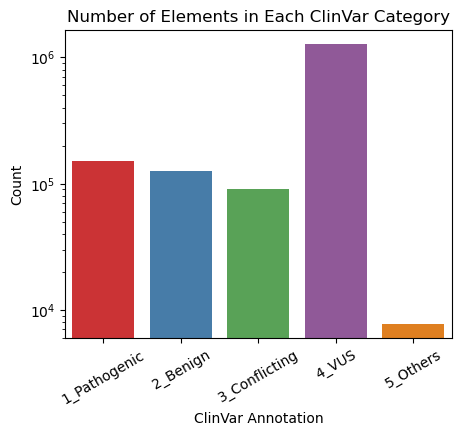

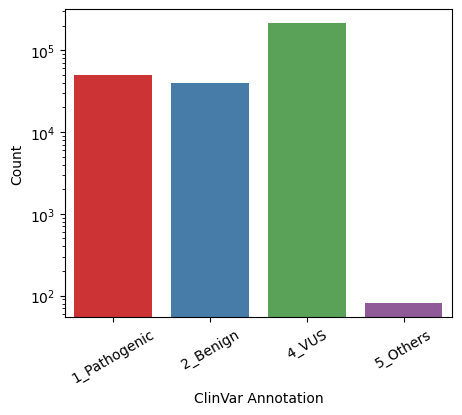

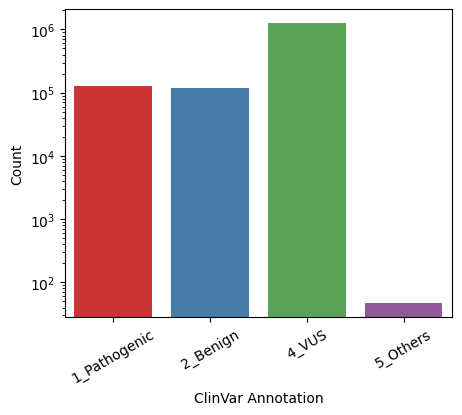

In [10]:
plot_by_cat(df_clinvar, "clinvar_clnsig_clean", title="Number of Elements in Each ClinVar Category")
plot_by_cat(df_clinvar.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")!="3_Conflicting")),
            "clinvar_clnsig_clean", title="")
plot_by_cat(df_clinvar.filter(pl.col("ReviewStatus").is_in([
                'practice guideline'
                'reviewed by expert panel',
                'criteria provided, multiple submitters, no conflicts',
                'criteria provided, single submitter'
            ])), "clinvar_clnsig_clean", title="")

In [ ]:
df_clinvar["StarStatus"].unique()
df_clinvar["ReviewStatus"].unique().to_list()

StarStatus
i32
null
1
2
3
4


In [20]:
def plot_ai_var_pred_dist(df, score_mapping, title):
    # Create a FacetGrid for multiple subplots
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5)) ## , sharey=True
    hue_order = sorted(df["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
    # Loop through variables and create subplots
    for ax, var in zip(axes, score_mapping.keys()):
        sns.kdeplot(
            data=df,
            x=var,
            hue="clinvar_clnsig_clean",
            hue_order=hue_order,
            common_norm=False,
            ax=ax,
            palette="Set1"
        )
        ax.set_title(var)
    
    plt.suptitle(title, y=.96)    
    plt.tight_layout()
    plt.show()

In [18]:
# Define the mapping from new column names to original column names
score_mapping = {
    "esm1b": "ESM1b_score",
    "alphamissense": "AlphaMissense_score",
    "provean": "PROVEAN_score"
}
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

df_clinvar_sampled_plots = df_clinvar.with_columns(
    [
        pl.col(score_mapping[var])
          .replace(".", None)
          .cast(pl.Float64)
          .alias(var)
        for var in score_mapping.keys()
    ]
).collect()
# .filter(
#     (pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")
# )

# df_clinvar_sampled_plots

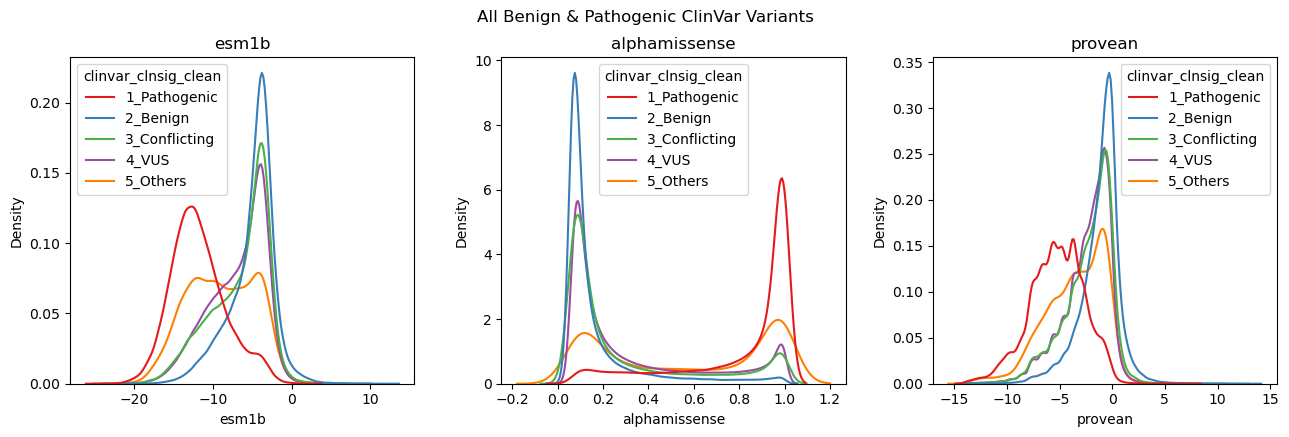

In [21]:
plot_ai_var_pred_dist(df_clinvar_sampled_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "All Benign & Pathogenic ClinVar Variants")

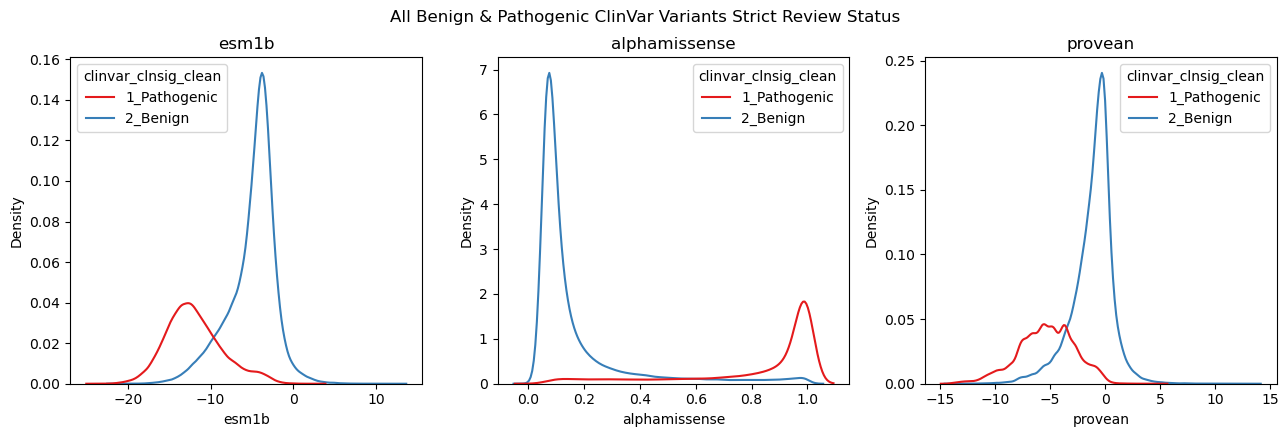

In [16]:
plot_ai_var_pred_dist(df_clinvar_sampled_plots.filter(pl.col("ReviewStatus").is_in([
                            'practice guideline'
                            'reviewed by expert panel',
                            'criteria provided, multiple submitters, no conflicts',
                            'criteria provided, single submitter'
                        ])).select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "All Benign & Pathogenic ClinVar Variants Strict Review Status")

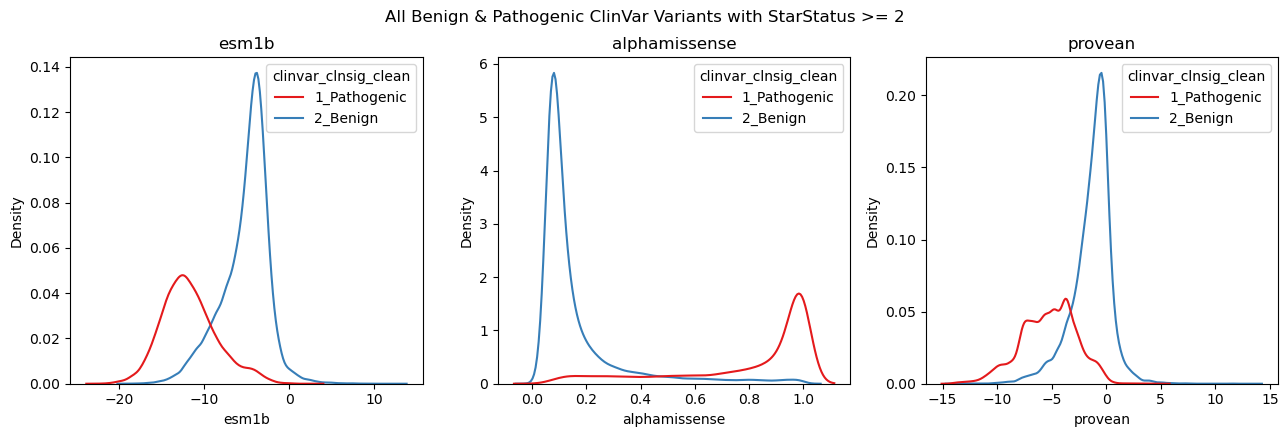

In [17]:
df_clinvar_sampled_plots.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")=="3_Conflicting")).select(predictor_algos+list(score_mapping.keys()))
## Among the Star>=2 variants, there is one conflicting variant, filter it out:
plot_ai_var_pred_dist(df_clinvar_sampled_plots.filter((pl.col("StarStatus").is_in([2, 3, 4]))&(pl.col("clinvar_clnsig_clean")!="3_Conflicting")).select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "All Benign & Pathogenic ClinVar Variants with StarStatus >= 2")

### ClinVAR alleles vs VarChAMP Alleles

In [23]:
varchamp_al_df_ai_plots = varchamp_al_df_ai_dedup.with_columns(
    [
        pl.col(score_mapping[var])
          .replace(".", None)
          .cast(pl.Float64)
          .alias(var)
        for var in score_mapping.keys()
    ]
)

varchamp_al_df_ai_plots

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,…,PhenotypeIDS_dbnsfp,PhenotypeList_dbnsfp,Origin_dbnsfp,OriginSimple_dbnsfp,Assembly_dbnsfp,ChromosomeAccession_dbnsfp,Chromosome_dbnsfp,Start_dbnsfp,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,esm1b,alphamissense,provean
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,…,str,str,str,str,str,str,str,i64,i64,str,str,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,f64,f64,f64
71569,"""OTC""","""240G>T""","""Lys80Asn""","""ENSG00000036473""","""X""",38369819,"""NC_000023.11:38369819:G:T""","""ALE00005236""","""CCSBVarC005236""","""NULL""","""205820""","""NULL""","""GDEhDisVCh_40048""","""B07""","""CEGS2""","""ATGCTGTTTAATCTGAGGATCCTGTTAAAC…",103032.0,"""single nucleotide variant""","""NM_000531.6(OTC):c.240G>T (p.L…",5009.0,"""OTC""","""HGNC:8512""","""Pathogenic""",1.0,"""-""",7.2554333e7,"""-""","""RCV000083371""","""MedGen:CN517202""","""not provided""","""unknown""","""unknown""","""GRCh38""","""NC_000023.11""","""X""",3.8369819e7,…,"""MedGen:CN517202""","""not provided""","""unknown""","""unknown""","""GRCh38""","""NC_000023.11""","""X""",38369819,38369819,"""Xp11.4""","""no assertion criteria provided""",1,"""ACMG2016,ACMG2021,ACMG2022""","""N""","""ClinGen:CA224512""",2,97140,38369819,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000115457""","""-""","""-""","""240G>T ""","""Lys80Asn""","""NM_000531.6""",null,"""1_Pathogenic""",-9.311,null,null
575,"""AGA""","""770C>T""","""Thr257Ile""","""ENSG00000038002""","""4""",177434418,"""NC_000004.12:177434418:G:A""","""ALE00005310""","""CCSBVarC005310""","""NULL""","""213789""","""NULL""","""GDEhDisVCh_40063""","""A09""","""CEGS2""","""ATGGCGCGGAAGTCGAACTTGCCTGTGCTT…",70592.0,"""single nucleotide variant""","""NM_000027.4(AGA):c.770C>T (p.T…",175.0,"""AGA""","""HGNC:318""","""Conflicting classifications of…",1.0,"""Aug 21, 2023""",3.86833434e8,"""-""","""RCV000049362""","""Human Phenotype Ontology:HP:00…","""Aspartylglucosaminuria""","""germline;unknown""","""germline""","""GRCh38""","""NC_000004.12""","""4""",1.77434418e8,…,"""Human Phenotype Ontology:HP:00…","""Aspartylglucosaminuria""","""germline;unknown""","""germline""","""GRCh38""","""NC_000004.12""","""4""",177434418,177434418,"""4q34.3""","""criteria provided, conflicting…",3,"""-""","""N""","""ClinGen:CA144033,UniProtKB:P20…",2,55953,177434418,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003525620|SCV004217649""","""-""","""-""","""770C>T ""","""Thr257Ile""","""NM_000027.4""",1,"""3_Conflicting""",-16.152,0.891,-5.72
3743,"""LAMP2""","""928G>A""","""Val310Ile""","""ENSG00000005893""","""X""",120442599,"""NC_000023.11:120442599:C:T""","""ALE00000542""","""CCSBVarC000542""","""6896""","""NULL""","""NULL""","""GDEhDisVCh_40087""","""G05""","""RC4""","""ATGGTGTGCTTCCGCCTCTTCCCG

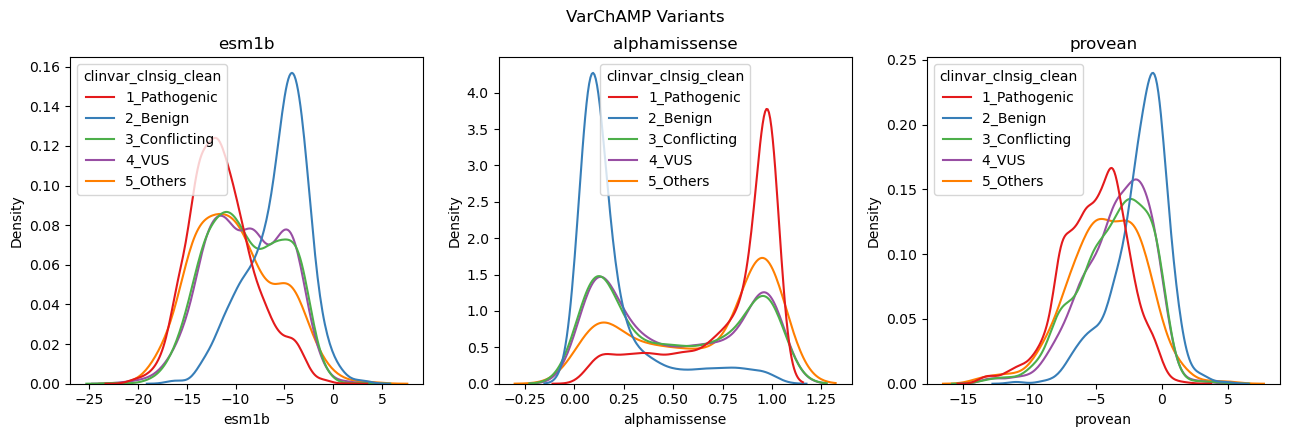

In [ ]:
plot_ai_var_pred_dist(varchamp_al_df_ai_plots.select(predictor_algos+list(score_mapping.keys())), 
                      score_mapping, "VarChAMP Variants")